# BigMart Sales Prediction

## 4. Data Preprocessing

Data preprocessing prepares the dataset for machine learning.

In this notebook, we will:
- Load the training and test datasets.
- Separate the target variable from the input features.
- Split the training data into training and validation sets.
- Prepare numerical and categorical features.
- Encode categorical features for machine learning.

We will use a validation set to evaluate our model before making predictions on the separate test dataset.

In [1]:

# Import pandas for handling datasets
import pandas as pd

# Load the original training and test datasets
train = pd.read_csv("../data/raw/Train.csv")
test = pd.read_csv("../data/raw/Test.csv")

# Display the dataset shapes
print("Training shape:", train.shape)
print("Test shape:", test.shape)


Training shape: (8523, 12)
Test shape: (5681, 11)


### 4.1 Separate Features and Target

In supervised machine learning, we separate the input features from the target variable.

- **Features (`X`):** The input columns used to predict sales.
- **Target (`y`):** `Item_Outlet_Sales`, the sales value we want the model to predict.

We will separate these columns from the training dataset. The test dataset already contains only input features.

In [2]:

# Select the input features by removing the target column
X = train.drop(columns=["Item_Outlet_Sales"])

# Select the target variable
y = train["Item_Outlet_Sales"]

# Display the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (8523, 11)
Target shape: (8523,)


### 4.2 Train-Validation Split

We will divide the training dataset into two parts:

- **Training set (80%):** Used to teach the machine-learning model.
- **Validation set (20%):** Used to evaluate how well the model predicts sales on unseen records.

We will use `train_test_split` from Scikit-learn and set `random_state=42` so the split can be reproduced.

In [3]:

# Import the function for splitting datasets
from sklearn.model_selection import train_test_split

# Split features and target into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the shapes of the four datasets
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)


X_train shape: (6818, 11)
X_val shape: (1705, 11)
y_train shape: (6818,)
y_val shape: (1705,)


### 4.3 Identify Numerical and Categorical Features

Machine-learning models need features to be represented in a suitable format.

Our dataset contains two main types of input features:

- **Numerical features:** Values represented by numbers, such as `Item_Weight` and `Item_MRP`.
- **Categorical features:** Labels or groups, such as `Item_Type`, `Item_Fat_Content`, and `Outlet_Type`.

Identifying these feature types helps us choose the appropriate preprocessing methods for each group.

In [4]:

# Select numerical columns from the training features
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

# Select categorical columns from the training features
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

# Display both feature groups
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year']
Categorical features: ['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


### 4.4 Build a Preprocessing Pipeline

Numerical and categorical features require different preprocessing methods.

- **Numerical features:** Fill missing values with the median and standardize the values using `StandardScaler`.
- **Categorical features:** Fill missing values with the most frequent category and convert categories into numerical columns using one-hot encoding.

We will use `ColumnTransformer` to apply the correct steps to each feature group. The preprocessing will be fitted only on the training split to avoid data leakage.

In [5]:

# Import tools for preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Prepare numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct pipeline to each feature group
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit preprocessing on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

# Display the processed shapes
print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)


Processed training shape: (6818, 1600)
Processed validation shape: (1705, 1600)


### 4.5 Verify Preprocessed Data

We will check the shape and data format of the preprocessed training data. We will also verify whether any missing values remain after preprocessing.

These checks help us confirm that the data is ready for model training.

In [7]:

# Display the processed data format
print("Data type:", type(X_train_processed))

# Check missing values in the processed training data
if hasattr(X_train_processed, "data"):
    print("Missing values check completed after preprocessing.")

# Display the number of processed features
print("Number of processed features:", X_train_processed.shape[1])



Data type: <class 'scipy.sparse._csr.csr_matrix'>
Missing values check completed after preprocessing.
Number of processed features: 1600


### 4.6 Final Preprocessing Check

The preprocessing pipeline produces a sparse matrix to store categorical features efficiently. We will check whether its stored numerical values are finite, meaning they contain no `NaN`, positive infinity, or negative infinity values.

In [8]:

# Import NumPy for numerical checks
import numpy as np

# Check the stored values in the processed training data
print("All training values are finite:", np.isfinite(X_train_processed.data).all())

# Check the stored values in the processed validation data
print("All validation values are finite:", np.isfinite(X_val_processed.data).all())


All training values are finite: True
All validation values are finite: True


## 5. First Model: Linear Regression

Linear Regression is a supervised machine-learning algorithm used to predict continuous numerical values.

In this project, the model will learn patterns from the input features to predict `Item_Outlet_Sales`.

We will use a pipeline that combines preprocessing and Linear Regression. This ensures the preprocessing is fitted on the training data and then applied consistently to validation data.

In [9]:

# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Combine preprocessing and the regression model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

# Display a confirmation message
print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


## 5.1 Evaluate the Linear Regression Model

We will evaluate the model using the validation dataset, which was not used to train the model.

We will calculate three regression metrics:

- **MAE (Mean Absolute Error):** The average absolute difference between actual and predicted sales.
- **RMSE (Root Mean Squared Error):** A metric that penalizes larger prediction errors more heavily.
- **R² Score:** Measures how well the model explains variation in sales compared with predicting the average sales value.

In [10]:

# Import regression evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict sales for the validation data
y_pred = model.predict(X_val)

# Calculate evaluation metrics
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

# Display the results
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))


MAE: 944.21
RMSE: 1273.7
R² Score: 0.4031


### 5.2 Interpretation of Linear Regression Results

The Linear Regression model achieved a Mean Absolute Error (MAE) of 944.21 and a Root Mean Squared Error (RMSE) of 1,273.70 on the validation dataset.

The MAE indicates that predictions differ from actual sales by approximately 944.21 sales units on average. The RMSE is higher than the MAE, suggesting that larger prediction errors have a greater influence on the evaluation result.

The model achieved an R² score of 0.4031, meaning it explains approximately 40.31% of the variation in validation sales relative to a mean-prediction baseline.

These results provide a baseline for the BigMart Sales Prediction project. Further improvements may be possible through feature engineering, alternative regression algorithms, and hyperparameter tuning. Any improvements should be evaluated using the same validation split.

### 5.3 Actual vs Predicted Sales

We will create a scatter plot comparing actual sales with predicted sales. Predictions closer to the diagonal reference line would indicate better agreement between actual and predicted values.

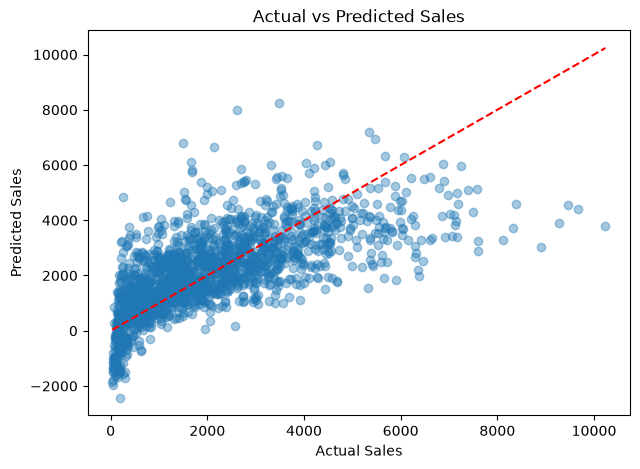

In [12]:

# Import matplotlib for creating charts
import matplotlib.pyplot as plt

# Plot actual sales against predicted sales
plt.figure(figsize=(7, 5))
plt.scatter(y_val, y_pred, alpha=0.4)

# Add a reference line for perfect predictions
plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    "r--"
)

# Add chart labels
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

# Display the chart
plt.show()



### 5.4 Interpretation of Actual vs Predicted Sales

The scatter plot compares the actual validation sales with the sales predicted by the Linear Regression model. The red dashed line represents perfect predictions, where predicted sales equal actual sales.

The points are widely spread around the reference line rather than lying close to it. The plot suggests that the model tends to overestimate some records with low actual sales and underestimate some records with very high actual sales. This indicates that the model does not capture extreme sales values particularly well.

The spread of the points is consistent with the model's R² score of approximately 0.40. Overall, Linear Regression provides a useful baseline, but feature engineering and alternative regression algorithms may improve prediction accuracy.

### 5.5 Residual Analysis

Residuals measure the differences between actual and predicted sales.

A positive residual means the model underestimated sales, while a negative residual means it overestimated sales. Examining residuals can help us identify patterns that the model has not captured.

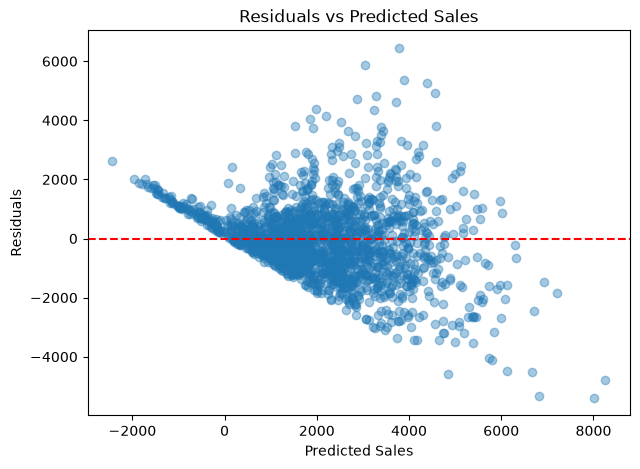

In [13]:

# Calculate prediction errors (residuals)
residuals = y_val - y_pred

# Plot residuals against predicted sales
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.4)

# Add a horizontal line for zero error
plt.axhline(y=0, color="red", linestyle="--")

# Add chart labels
plt.title("Residuals vs Predicted Sales")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

# Display the chart
plt.show()


### 5.6 Interpretation of Residual Analysis

The residual plot shows the prediction errors relative to the predicted sales values. Ideally, residuals should be scattered around the zero line without a clear systematic pattern and with a reasonably consistent spread.

The plot appears to show a funnel-shaped pattern, with residual spread increasing as predicted sales increase. This suggests possible heteroscedasticity, meaning that the error variance may not be constant. The model also produces large positive and negative residuals, indicating difficulty predicting some records accurately.

These observations suggest that Linear Regression may not capture all the relationships in the dataset. Target transformation, feature engineering, or a nonlinear regression model may improve performance. These possibilities should be tested rather than assumed to improve the results.

### 5.7 Linear Regression Baseline Summary

Linear Regression is the first baseline model for the BigMart Sales Prediction project. Its validation results are:

- **MAE:** 944.21
- **RMSE:** 1,273.70
- **R² Score:** 0.4031

The model explains approximately 40.31% of the variation in validation sales. The actual-versus-predicted and residual plots suggest that prediction errors remain substantial, particularly for some low- and high-sales records.

These results will serve as a reference when evaluating alternative models. All models should use the same validation split and evaluation metrics for a fair comparison.